# 02 Forecasting Bangladesh garment imports into the US and EU

This notebook forecasts monthly imports of Bangladeshi garments (HS 61 and 62) as the importers report them, in current US dollars. It covers US and EU totals, the 12 US product groups, and EU knit and woven.

Steps:
1. Backtest five models and two equal-weight ensembles with a rolling origin and a 12-month horizon.
2. Score each one on monthly error and on the error of the 12-month and quarterly totals.
3. Pick a model for each series with the rule below.
4. Refit that model on all data and forecast the next 12 months with 80% and 95% intervals.

The model code is in `src/models.py`. The first version of this notebook picked models on monthly MASE alone. Its tables and figures are kept in `outputs/archive_v1/` for comparison.

In [1]:
import sys, warnings, logging
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import models as M
logging.getLogger("cmdstanpy").disabled = True

ROOT = ".."
TAB, FIG = f"{ROOT}/outputs/tables", f"{ROOT}/outputs/figures"
SOURCE = "Source: UN Comtrade (US-reported imports) and Eurostat Comext (EU27 imports, EUR converted at ECB rates); author's forecasts. Nominal USD, CIF."
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 9})
series = M.load_series(f"{ROOT}/data/processed/rmg_long.csv")
pd.DataFrame({k: [v.index[0].strftime('%Y-%m'), v.index[-1].strftime('%Y-%m'), round(v[-12:].sum()/1e9, 2)]
              for k, v in series.items()}, index=["first", "last", "last 12m, $bn"]).T

,first,last,"last 12m, $bn"
EU | Total,1999-01,2026-08,20.82
EU | Knit,1999-01,2026-08,12.56
EU | Woven,1999-01,2026-08,8.26
US | Total,2010-01,2026-07,7.9
US | Knit: Coats & jackets,2010-01,2026-07,0.1
US | Knit: Knit shirts & blouses,2010-01,2026-07,0.28
US | Knit: Knit suits & trousers,2010-01,2026-07,0.41
US | Knit: Other apparel,2010-01,2026-07,0.31
US | Knit: Sweaters & pullovers (knit),2010-01,2026-07,0.84
US | Knit: T-shirts & vests (knit),2010-01,2026-07,0.56


## Setup

- **Models.** Seasonal naive (same month last year) is the baseline. ETS is additive with a damped trend. SARIMA picks its order by AIC from a small grid. Prophet uses yearly seasonality. LightGBM uses lags 1, 2, 3, 6 and 12, 3- and 12-month rolling means, and month of year, and it forecasts recursively. It predicts the change from the same month a year earlier, because trees cannot extrapolate a level.
- **COVID.** SARIMA and LightGBM get a dummy for March to August 2020, and Prophet treats those months as a holiday. LightGBM also gets a flag for months whose lag-12 value falls in that window, which covers the 2021 rebound.
- **Logs.** Every model except the seasonal naive is fit on log values and then back-transformed.
- **Ensembles.** "Ensemble" is the mean of the log forecasts of ETS, SARIMA, Prophet and LightGBM. "Ensemble (no LGBM)" drops LightGBM. The members are fixed in advance, not picked from the backtest, so the ensembles do not get an unfair look at the test data.
- **Backtest.** There are seven origins, every six months from July 2022 to July 2025. Each origin is the last month of training, and the next 12 months are the test set. MASE is scaled by the in-sample seasonal naive error, so a value below 1 beats last year's pattern on the training data. Relative MASE divides each model's mean MASE by the seasonal naive's mean MASE for the same series and origins. Below 1 means the model beat the naive on the test data.
- **Metrics.** Monthly MAPE, RMSE and MASE measure month-by-month accuracy. Two more metrics measure totals, which is what most planning uses: `APE_12m` is the absolute percent error of the 12-month sum, and `APE_q` is the mean absolute percent error of the four quarterly sums. `bias_12m` is the signed error of the 12-month sum (positive means the forecast was too high).

In [2]:
ORIGINS = pd.date_range("2022-07-01", "2025-07-01", freq="6MS")
models = M.available_models()
print("Models:", list(models), "+", list(M.ENSEMBLES))
_, errs = M.backtest(series, ORIGINS, models)
errs = M.add_ensembles(errs)
bt = M.metrics_from_errors(errs)
bt.to_csv(f"{TAB}/backtest_metrics.csv", index=False)
summary = bt.groupby(["series", "model"])[["MAPE", "RMSE", "MASE", "APE_12m", "APE_q", "bias_12m"]].mean().reset_index()
# Relative MASE: model MASE / seasonal-naive MASE on the same series and origins (below 1 beats the naive)
sn_mase = summary[summary.model == "Seasonal naive"].set_index("series").MASE
summary["rel_MASE"] = summary.MASE / summary.series.map(sn_mase)
summary.to_csv(f"{TAB}/backtest_summary.csv", index=False)
summary.pivot(index="series", columns="model", values="MASE").round(2)

Models: ['Seasonal naive', 'ETS', 'SARIMA', 'Prophet', 'LightGBM'] + ['Ensemble', 'Ensemble (no LGBM)']


/Users/taky_tahmid/miniconda3/envs/crop_env/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/Users/taky_tahmid/miniconda3/envs/crop_env/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/Users/taky_tahmid/miniconda3/envs/crop_env/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/Users/taky_tahmid/miniconda3/envs/crop_env/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


...

/Users/taky_tahmid/miniconda3/envs/crop_env/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/Users/taky_tahmid/miniconda3/envs/crop_env/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/Users/taky_tahmid/miniconda3/envs/crop_env/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/Users/taky_tahmid/miniconda3/envs/crop_env/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


model,ETS,Ensemble,Ensemble (no LGBM),LightGBM,Prophet,SARIMA,Seasonal naive
series,,,,,,,
EU | Knit,2.22,2.41,2.14,3.91,2.17,2.43,2.63
EU | Total,2.10,2.17,1.98,3.48,1.94,2.33,2.52
EU | Woven,1.82,1.77,1.68,2.35,1.70,2.04,2.25
US | Knit: Coats & jackets,1.09,1.07,1.07,1.53,1.31,0.98,1.20
US | Knit: Knit shirts & blouses,1.23,1.43,1.29,2.61,2.70,1.23,1.56
US | Knit: Knit suits & trousers,1.10,1.73,1.65,3.15,2.94,1.37,1.61
US | Knit: Other apparel,1.46,1.87,1.88,2.06,2.71,1.74,1.85
US | Knit: Sweaters & pullovers (knit),1.09,1.49,1.38,2.22,2.08,1.37,1.46
US | Knit: T-shirts & vests (knit),1.55,2.39,2.12,4.07,3.44,2.18,2.46


## Relative MASE and the error of the totals

Monthly MASE is above 1 for almost every model and series, including the seasonal naive itself. MASE divides by the seasonal naive error on the training data, and the 2022 to 2026 test window was rougher than the years before it. So MASE above 1 does not mean "worse than naive". The direct comparison is relative MASE: the model's MASE divided by the seasonal naive's MASE on the same origins. The table below shows it. Monthly values also move a lot with shipment timing and the Eid holidays, which shift by about 11 days a year. Totals over a quarter or a year smooth most of that out.


In [3]:
summary.pivot(index="series", columns="model", values="rel_MASE").round(2)

model,ETS,Ensemble,Ensemble (no LGBM),LightGBM,Prophet,SARIMA,Seasonal naive
series,,,,,,,
EU | Knit,0.85,0.92,0.82,1.49,0.83,0.92,1.0
EU | Total,0.83,0.86,0.78,1.38,0.77,0.92,1.0
EU | Woven,0.81,0.79,0.75,1.04,0.75,0.91,1.0
US | Knit: Coats & jackets,0.90,0.89,0.89,1.27,1.09,0.82,1.0
US | Knit: Knit shirts & blouses,0.79,0.92,0.83,1.67,1.73,0.79,1.0
US | Knit: Knit suits & trousers,0.68,1.07,1.02,1.95,1.82,0.85,1.0
US | Knit: Other apparel,0.79,1.01,1.02,1.12,1.47,0.94,1.0
US | Knit: Sweaters & pullovers (knit),0.75,1.02,0.94,1.52,1.43,0.94,1.0
US | Knit: T-shirts & vests (knit),0.63,0.97,0.86,1.66,1.40,0.89,1.0


In [4]:
summary.pivot(index="series", columns="model", values="APE_12m").round(1)

model,ETS,Ensemble,Ensemble (no LGBM),LightGBM,Prophet,SARIMA,Seasonal naive
series,,,,,,,
EU | Knit,14.6,16.5,13.7,26.4,12.5,17.6,13.5
EU | Total,13.0,12.6,11.5,21.2,8.9,15.7,12.2
EU | Woven,11.1,9.2,8.9,12.5,7.5,13.4,10.3
US | Knit: Coats & jackets,16.3,16.7,16.0,25.8,20.9,13.8,13.4
US | Knit: Knit shirts & blouses,10.5,12.3,9.5,25.7,34.9,8.6,11.2
US | Knit: Knit suits & trousers,16.9,29.0,27.6,55.0,52.4,22.0,24.9
US | Knit: Other apparel,16.4,23.9,24.1,24.0,36.2,20.3,20.4
US | Knit: Sweaters & pullovers (knit),10.7,16.9,13.9,26.9,25.8,14.6,14.1
US | Knit: T-shirts & vests (knit),17.1,28.7,25.2,46.3,45.5,26.8,26.5


In [5]:
summary.pivot(index="series", columns="model", values="APE_q").round(1)

model,ETS,Ensemble,Ensemble (no LGBM),LightGBM,Prophet,SARIMA,Seasonal naive
series,,,,,,,
EU | Knit,15.8,17.7,15.3,28.5,15.4,18.4,17.3
EU | Total,14.1,14.2,13.2,23.6,11.2,16.5,15.5
EU | Woven,12.4,11.8,11.0,15.7,8.3,14.4,13.8
US | Knit: Coats & jackets,19.3,19.6,18.8,32.2,24.4,17.0,20.6
US | Knit: Knit shirts & blouses,12.6,16.9,14.2,34.3,35.7,12.8,16.8
US | Knit: Knit suits & trousers,18.6,31.2,29.9,62.0,55.8,24.0,28.5
US | Knit: Other apparel,18.2,25.1,24.8,27.9,37.1,22.7,22.9
US | Knit: Sweaters & pullovers (knit),12.1,18.4,16.0,30.0,27.0,16.0,18.8
US | Knit: T-shirts & vests (knit),21.5,32.7,28.7,57.4,48.5,30.6,34.7


## Model choice

The rule: take the models whose mean 12-month-total APE is within 1 percentage point of the lowest for that series, and among those pick the one with the lowest mean monthly MASE. Any tie left goes to the simpler model. The 1-point band is there because seven origins cannot separate models that close.

In [6]:
best = M.pick_best_total(summary)
best.to_csv(f"{TAB}/best_model_by_series.csv", index=False)
best.assign(RMSE_musd=(best.RMSE/1e6).round(1)).drop(columns="RMSE").round(2)

,series,model,MAPE,MASE,APE_12m,APE_q,bias_12m,rel_MASE,RMSE_musd
0,EU | Knit,Prophet,17.38,2.17,12.49,15.44,11.06,0.83,197.7
1,EU | Total,Prophet,14.70,1.94,8.87,11.25,5.91,0.77,276.9
2,EU | Woven,Prophet,12.70,1.70,7.50,8.31,-1.28,0.75,100.7
3,US | Knit: Coats & jackets,SARIMA,24.65,0.98,13.82,16.96,9.03,0.82,2.2
4,US | Knit: Knit shirts & blouses,SARIMA,17.24,1.23,8.60,12.82,3.20,0.79,4.0
5,US | Knit: Knit suits & trousers,ETS,22.04,1.10,16.94,18.64,2.67,0.68,8.3
6,US | Knit: Other apparel,ETS,20.92,1.46,16.40,18.23,2.31,0.79,5.0
7,US | Knit: Sweaters & pullovers (knit),ETS,15.50,1.09,10.72,12.10,1.28,0.75,11.1
8,US | Knit: T-shirts & vests (knit),ETS,23.06,1.55,17.11,21.50,5.81,0.63,11.9
9,US | Knit: Underwear & nightwear,ETS,16.92,0.96,10.81,14.44,0.94,0.68,6.5


In [7]:
# Mean scores by model across all series, and how often each model wins
agg = summary.groupby("model")[["MASE", "APE_12m", "APE_q"]].mean().round(2)
agg["wins"] = best["model"].value_counts().reindex(agg.index).fillna(0).astype(int)
agg.sort_values("APE_12m")

,MASE,APE_12m,APE_q,wins
model,,,,
ETS,1.40,14.48,17.04,10
Seasonal naive,1.76,16.34,21.12,1
SARIMA,1.57,16.97,19.42,2
Ensemble (no LGBM),1.57,17.31,19.91,0
Ensemble,1.66,18.73,21.17,0
Prophet,2.19,28.26,30.35,3
LightGBM,2.54,29.69,34.41,0


In [8]:
# US and EU totals: seasonal naive vs best single model vs ensembles
single = [m for m in models if m != "Seasonal naive"]
cmp = []
for s in ["US | Total", "EU | Total"]:
    t = summary[summary.series == s].set_index("model")
    bs = t.loc[single, "APE_12m"].idxmin()
    for lab, m in [("Seasonal naive", "Seasonal naive"), (f"Best single ({bs})", bs),
                   ("Ensemble", "Ensemble"), ("Ensemble (no LGBM)", "Ensemble (no LGBM)")]:
        cmp.append({"series": s, "model": lab, **t.loc[m, ["MASE", "MAPE", "APE_q", "APE_12m", "bias_12m"]].to_dict()})
pd.DataFrame(cmp).round(2)

,series,model,MASE,MAPE,APE_q,APE_12m,bias_12m
0,US | Total,Seasonal naive,1.76,22.27,19.62,16.32,6.92
1,US | Total,Best single (ETS),1.36,17.56,15.50,13.95,5.49
2,US | Total,Ensemble,1.86,24.21,21.93,20.67,13.74
3,US | Total,Ensemble (no LGBM),1.63,21.21,18.55,16.44,10.04
4,EU | Total,Seasonal naive,2.52,18.79,15.55,12.22,2.08
5,EU | Total,Best single (Prophet),1.94,14.70,11.25,8.87,5.91
6,EU | Total,Ensemble,2.17,16.48,14.24,12.63,6.44
7,EU | Total,Ensemble (no LGBM),1.98,15.00,13.23,11.52,5.81


What the backtest shows:

- The seasonal naive does not score 1 on its own test data. Its mean monthly MASE is 1.76 for the US total and 2.52 for the EU total. ETS beats it for the US (1.36), and Prophet beats it for the EU (1.94). As relative MASE, that is 0.77 for both: the chosen models cut the naive's monthly error by about a quarter. ETS scores below 1 on 15 of 16 series. The chosen model beats the naive on 15 series, and the naive itself is kept for US woven coats and jackets.
- On the 12-month total, the chosen models miss by about 14% (US, ETS) and 9% (EU, Prophet) on average, against 16% and 12% for the seasonal naive. Quarterly totals miss by 15.5% (US) and 11% (EU).
- Most models over-forecast the 12-month total on average (positive `bias_12m`): by about 5.5% for US ETS and 6% for EU Prophet. Most of it comes from the January and July 2023 origins, which projected the 2022 peak forward just as imports fell. ETS missed the US total by 40% from the January 2023 origin. The 2024 origins under-forecast.
- Neither ensemble wins on any series. Averaging pulls the good models toward the weak ones, LightGBM in particular. Without LightGBM the ensemble lands between the best and worst members.
- Under the new rule, 15 of 16 series keep their v1 model. US knit shirts and blouses moves from ETS to SARIMA.

## Backtest chart

The left panel shows mean monthly MASE by model for the two market totals. The middle panel shows relative MASE (the seasonal naive is 1 by construction). The right panel shows the mean error of the 12-month total.


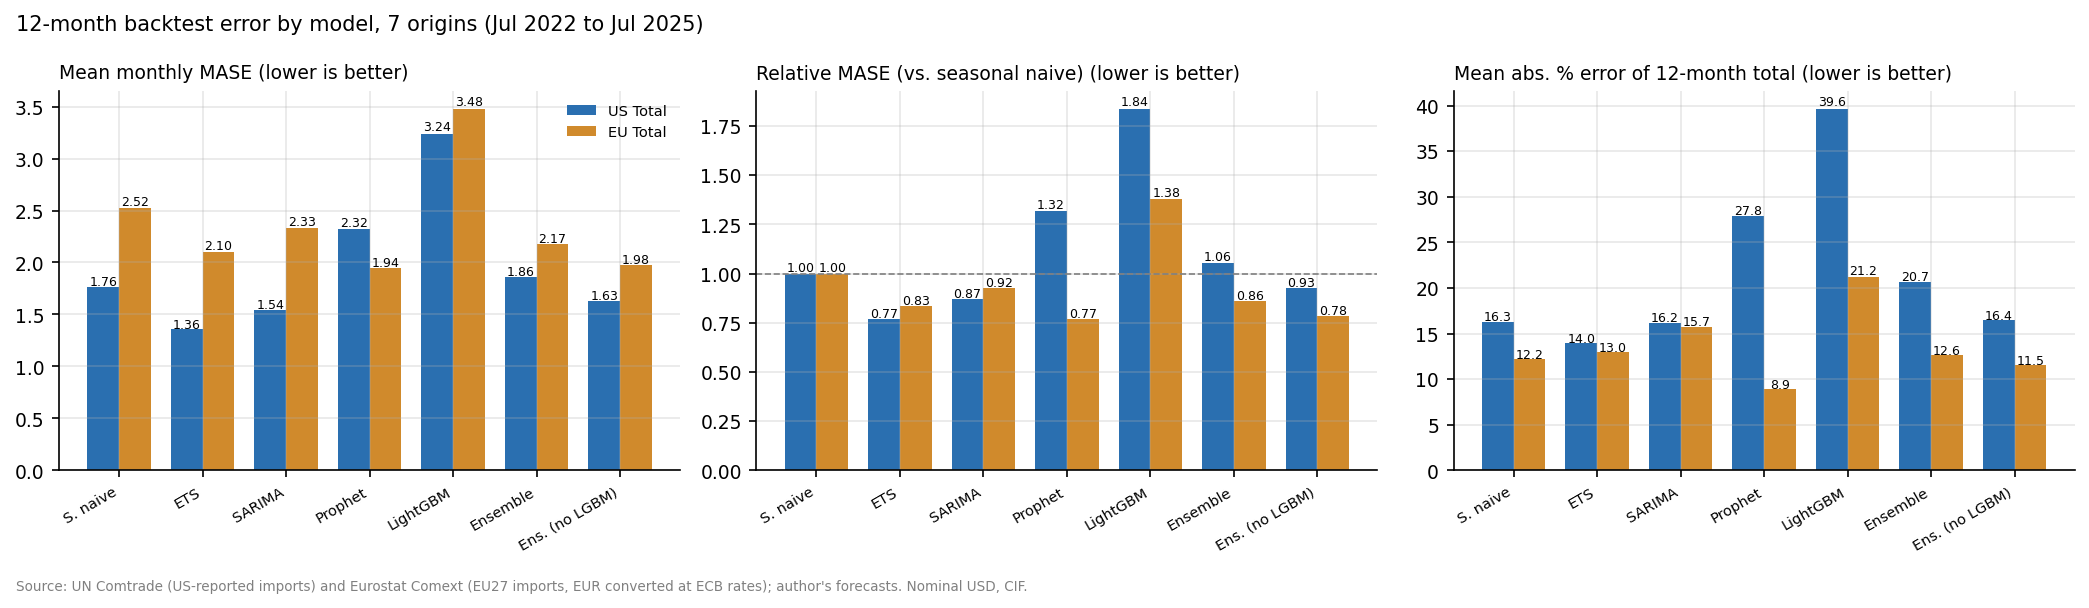

In [9]:
order = list(models) + list(M.ENSEMBLES)
labels = [o.replace("Seasonal naive", "S. naive").replace("Ensemble (no LGBM)", "Ens. (no LGBM)") for o in order]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
tot = summary[summary.series.isin(["US | Total", "EU | Total"])]
w = 0.38
for ax, met, lab in [(axes[0], "MASE", "Mean monthly MASE"), (axes[1], "rel_MASE", "Relative MASE (vs. seasonal naive)"), (axes[2], "APE_12m", "Mean abs. % error of 12-month total")]:
    for i, (s, col) in enumerate([("US | Total", "#2a6fb0"), ("EU | Total", "#d08a2c")]):
        v = tot[tot.series == s].set_index("model").reindex(order)[met]
        xs = np.arange(len(order)) + (i - 0.5) * w
        ax.bar(xs, v, w, label=s.replace(" | ", " "), color=col)
        for x, val in zip(xs, v):
            ax.text(x, val * 1.01, f"{val:.1f}" if met == "APE_12m" else f"{val:.2f}", ha="center", fontsize=6)
    ax.set_xticks(range(len(order)), labels, rotation=30, ha="right", fontsize=7)
    ax.set_title(lab + " (lower is better)", loc="left", fontsize=9)
axes[1].axhline(1, color="grey", lw=0.8, ls="--")
axes[0].legend(frameon=False, fontsize=7)
fig.suptitle("12-month backtest error by model, 7 origins (Jul 2022 to Jul 2025)", x=0.01, ha="left", fontsize=10)
fig.text(0.01, -0.03, SOURCE, fontsize=6.5, color="grey")
fig.tight_layout(); fig.savefig(f"{FIG}/backtest_mase_by_model.png", bbox_inches="tight"); plt.show()

## Final forecast

Each series is refit on all its data with its best model. SARIMA intervals come from the model itself, on the log scale. For the other models and the ensembles the intervals come from backtest errors: for horizon *k*, the quantiles of log(actual / forecast) across all origins at horizons *k*-2 to *k*+2. These intervals are only as wide as the errors seen in 2022 to 2026, so a shock the size of COVID would fall outside them.

In [10]:
best_map = dict(zip(best.series, best.model))
rows = []
for name, y in series.items():
    m = best_map[name]
    e = errs[(errs.series == name) & (errs.model == m)]
    fc = M.final_forecast(y, m, e)
    mkt, grp = name.split(" | ")
    fc = fc.assign(market=mkt, product_group=grp, model=m).rename_axis("date").reset_index()
    rows.append(fc)
fc_all = pd.concat(rows)[["date", "market", "product_group", "model", "point", "lo80", "hi80", "lo95", "hi95"]]
fc_all.to_csv(f"{TAB}/forecast_12m.csv", index=False)
fc_all.head()

,date,market,product_group,model,point,lo80,hi80,lo95,hi95
0,2026-09-01,EU,Total,Prophet,2.081661e+09,1.617397e+09,2.441630e+09,1.581663e+09,2.583798e+09
1,2026-10-01,EU,Total,Prophet,1.731298e+09,1.367947e+09,2.083353e+09,1.323354e+09,2.222815e+09
2,2026-11-01,EU,Total,Prophet,1.530873e+09,1.191485e+09,1.850491e+09,1.169183e+09,1.951428e+09
3,2026-12-01,EU,Total,Prophet,1.539777e+09,1.223689e+09,1.861254e+09,1.128943e+09,1.962778e+09
4,2027-01-01,EU,Total,Prophet,1.975658e+09,1.538552e+09,2.388139e+09,1.425459e+09,2.518401e+09


In [11]:
# Headline: next 12 months vs last 12 observed months
head = []
for name in series:
    y = series[name]; f = fc_all[(fc_all.market + " | " + fc_all.product_group) == name]
    head.append({"series": name, "model": best_map[name],
                 "last 12m ($bn)": y[-12:].sum() / 1e9, "next 12m ($bn)": f.point.sum() / 1e9,
                 "forecast window": f"{f.date.min():%Y-%m} to {f.date.max():%Y-%m}"})
head = pd.DataFrame(head)
head["change %"] = (head["next 12m ($bn)"] / head["last 12m ($bn)"] - 1) * 100
head.to_csv(f"{TAB}/forecast_headline.csv", index=False)
head.round(2)

,series,model,last 12m ($bn),next 12m ($bn),forecast window,change %
0,EU | Total,Prophet,20.82,22.53,2026-09 to 2027-08,8.23
1,EU | Knit,Prophet,12.56,13.43,2026-09 to 2027-08,6.94
2,EU | Woven,Prophet,8.26,8.97,2026-09 to 2027-08,8.61
3,US | Total,ETS,7.90,7.95,2026-08 to 2027-07,0.71
4,US | Knit: Coats & jackets,SARIMA,0.10,0.11,2026-08 to 2027-07,10.32
5,US | Knit: Knit shirts & blouses,SARIMA,0.28,0.28,2026-08 to 2027-07,-0.18
6,US | Knit: Knit suits & trousers,ETS,0.41,0.37,2026-08 to 2027-07,-9.74
7,US | Knit: Other apparel,ETS,0.31,0.33,2026-08 to 2027-07,6.18
8,US | Knit: Sweaters & pullovers (knit),ETS,0.84,0.95,2026-08 to 2027-07,13.05
9,US | Knit: T-shirts & vests (knit),ETS,0.56,0.52,2026-08 to 2027-07,-7.51


## Do the groups add up to the totals?

Each series has its own model, so the product groups do not sum exactly to the market-total forecast. The check below compares them. The gap is under 1% for both markets. The scenarios in `03_scenarios` use the group sums. The fan charts and the headline table use the total models. No reconciliation is applied, since the gap is well inside the forecast intervals.


In [12]:
coh = (fc_all.assign(level=np.where(fc_all.product_group.eq("Total"), "total_model", "sum_of_groups"))
         .groupby(["market", "level"]).point.sum().unstack() / 1e9)
coh["gap_pct"] = (coh.sum_of_groups / coh.total_model - 1) * 100
assert coh.gap_pct.abs().max() < 1, "group sums differ from total model by 1% or more"
coh.round(3)

level,sum_of_groups,total_model,gap_pct
market,,,
EU,22.397,22.529,-0.584
US,7.899,7.952,-0.665


## Power BI table

`fact_forecast.csv` uses the same keys as `fact_exports.csv`: `date_key` (YYYYMMDD), `market_key` and `product_key`. Market-total rows use the "All products" member of `dim_product` (its `is_total` flag is 1), and `level` is "Total". Filter on `is_total = 0` before summing product groups, or the totals will be counted twice. Forecast dates run past the end of `dim_date`, so any missing dates are appended to that table. Dates already there are not added again.


In [13]:
PB = f"{ROOT}/data/processed/powerbi"
dmk = pd.read_csv(f"{PB}/dim_market.csv"); dpr = pd.read_csv(f"{PB}/dim_product.csv"); ddt = pd.read_csv(f"{PB}/dim_date.csv")
f = fc_all.copy()
f["chapter"] = f.product_group.str.split(":").str[0]
f["pg"] = f.product_group.str.split(": ").str[1]
eu = f.market.eq("EU") & f.product_group.ne("Total")
f.loc[eu, "pg"] = f.loc[eu, "chapter"].map({"Knit": "Knit (HS61, all)", "Woven": "Woven (HS62, all)"})
f = f.merge(dpr[["product_key", "chapter", "product_group"]].rename(columns={"product_group": "pg"}),
            on=["chapter", "pg"], how="left").merge(dmk[["market_key", "market"]], on="market")
f["level"] = np.where(f.product_group.eq("Total"), "Total", "Product group")
f["date_key"] = f.date.dt.strftime("%Y%m%d").astype(int)
all_key = dpr.loc[dpr.product_group.eq("All products"), "product_key"].item()
f.loc[f.level.eq("Total"), "product_key"] = all_key
f["product_key"] = f.product_key.astype("Int64")
assert f["product_key"].notna().all()
fact = f[["date_key", "market_key", "product_key", "level", "model", "point", "lo80", "hi80", "lo95", "hi95"]]
fact.to_csv(f"{PB}/fact_forecast.csv", index=False)

new = sorted(set(f.date) - set(pd.to_datetime(ddt.date)))
if new:
    nd = pd.DataFrame({"date": new})
    add = pd.DataFrame({"date_key": nd.date.dt.strftime("%Y%m%d").astype(int), "date": nd.date.dt.strftime("%Y-%m-%d"),
                        "year": nd.date.dt.year, "quarter": nd.date.dt.quarter, "month": nd.date.dt.month,
                        "month_name": nd.date.dt.strftime("%b"),
                        "bd_fiscal_year": np.where(nd.date.dt.month >= 7, nd.date.dt.year + 1, nd.date.dt.year)})
    pd.concat([ddt, add]).drop_duplicates("date_key").to_csv(f"{PB}/dim_date.csv", index=False)
print(len(fact), "forecast rows;", len(new), "dates added to dim_date")

192 forecast rows; 0 dates added to dim_date


## Fan charts for the market totals

Each chart shows the last four years of actuals and the 12-month forecast with 80% and 95% bands.

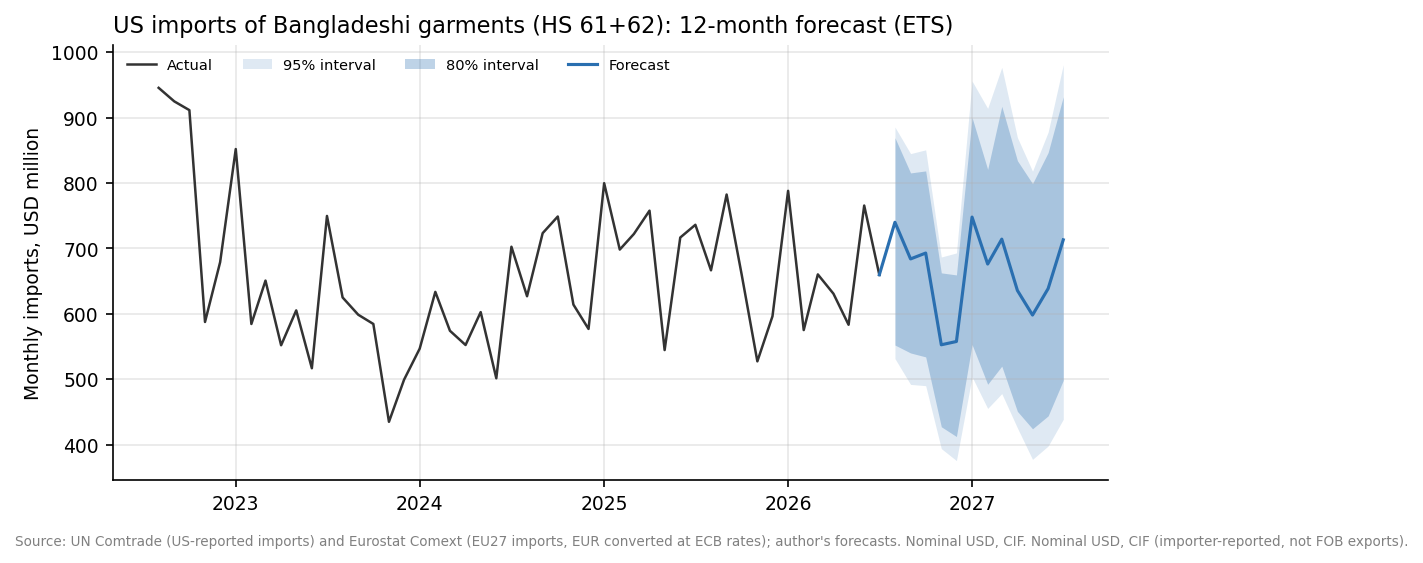

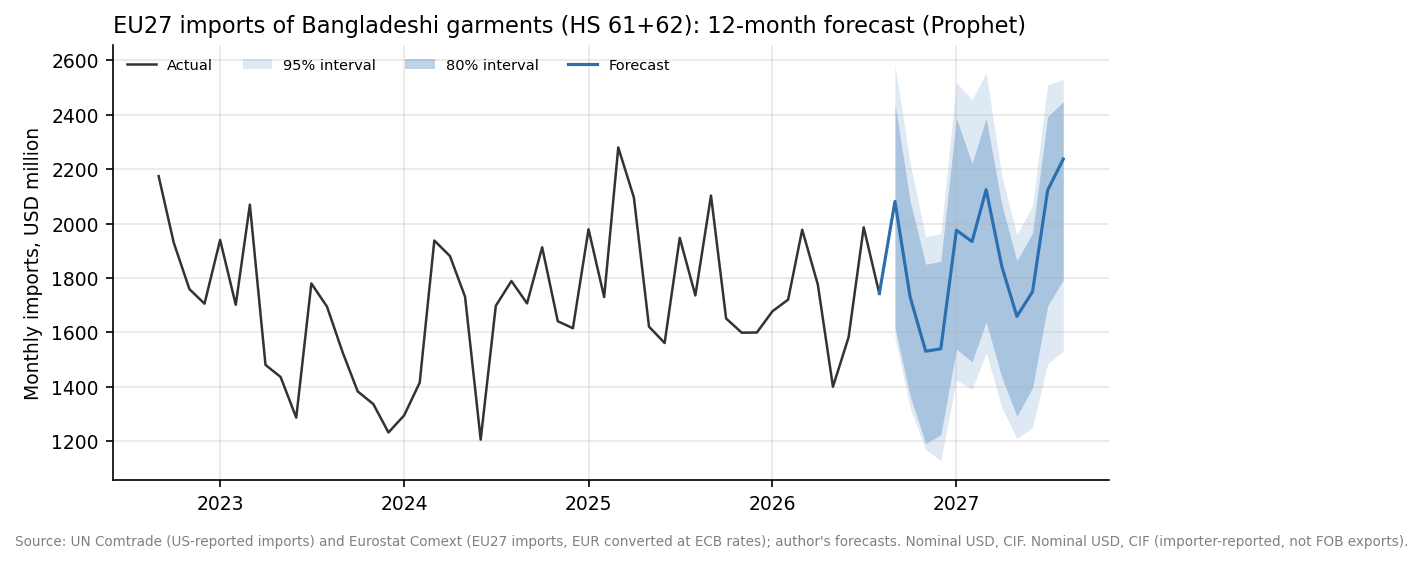

In [14]:
def fan(name, ax):
    y = series[name] / 1e6
    f = fc_all[(fc_all.market + " | " + fc_all.product_group) == name].set_index("date")
    y4 = y[y.index > y.index[-1] - pd.DateOffset(years=4)]
    ax.plot(y4.index, y4, c="#333", lw=1.2, label="Actual")
    ax.fill_between(f.index, f.lo95 / 1e6, f.hi95 / 1e6, color="#2a6fb0", alpha=0.15, lw=0, label="95% interval")
    ax.fill_between(f.index, f.lo80 / 1e6, f.hi80 / 1e6, color="#2a6fb0", alpha=0.3, lw=0, label="80% interval")
    ax.plot([y4.index[-1]] + list(f.index), [y4.iloc[-1]] + list(f.point / 1e6), c="#2a6fb0", lw=1.5, label="Forecast")
    ax.set_ylabel("Monthly imports, USD million")

for name, fn in [("US | Total", "fan_us_total.png"), ("EU | Total", "fan_eu_total.png")]:
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    fan(name, ax)
    mkt = "US" if name.startswith("US") else "EU27"
    ax.set_title(f"{mkt} imports of Bangladeshi garments (HS 61+62): 12-month forecast ({best_map[name]})", loc="left")
    ax.legend(frameon=False, ncol=4, fontsize=7, loc="upper left")
    fig.text(0.01, -0.02, SOURCE + " Nominal USD, CIF (importer-reported, not FOB exports).", fontsize=6.5, color="grey")
    fig.tight_layout(); fig.savefig(f"{FIG}/{fn}", bbox_inches="tight"); plt.show()

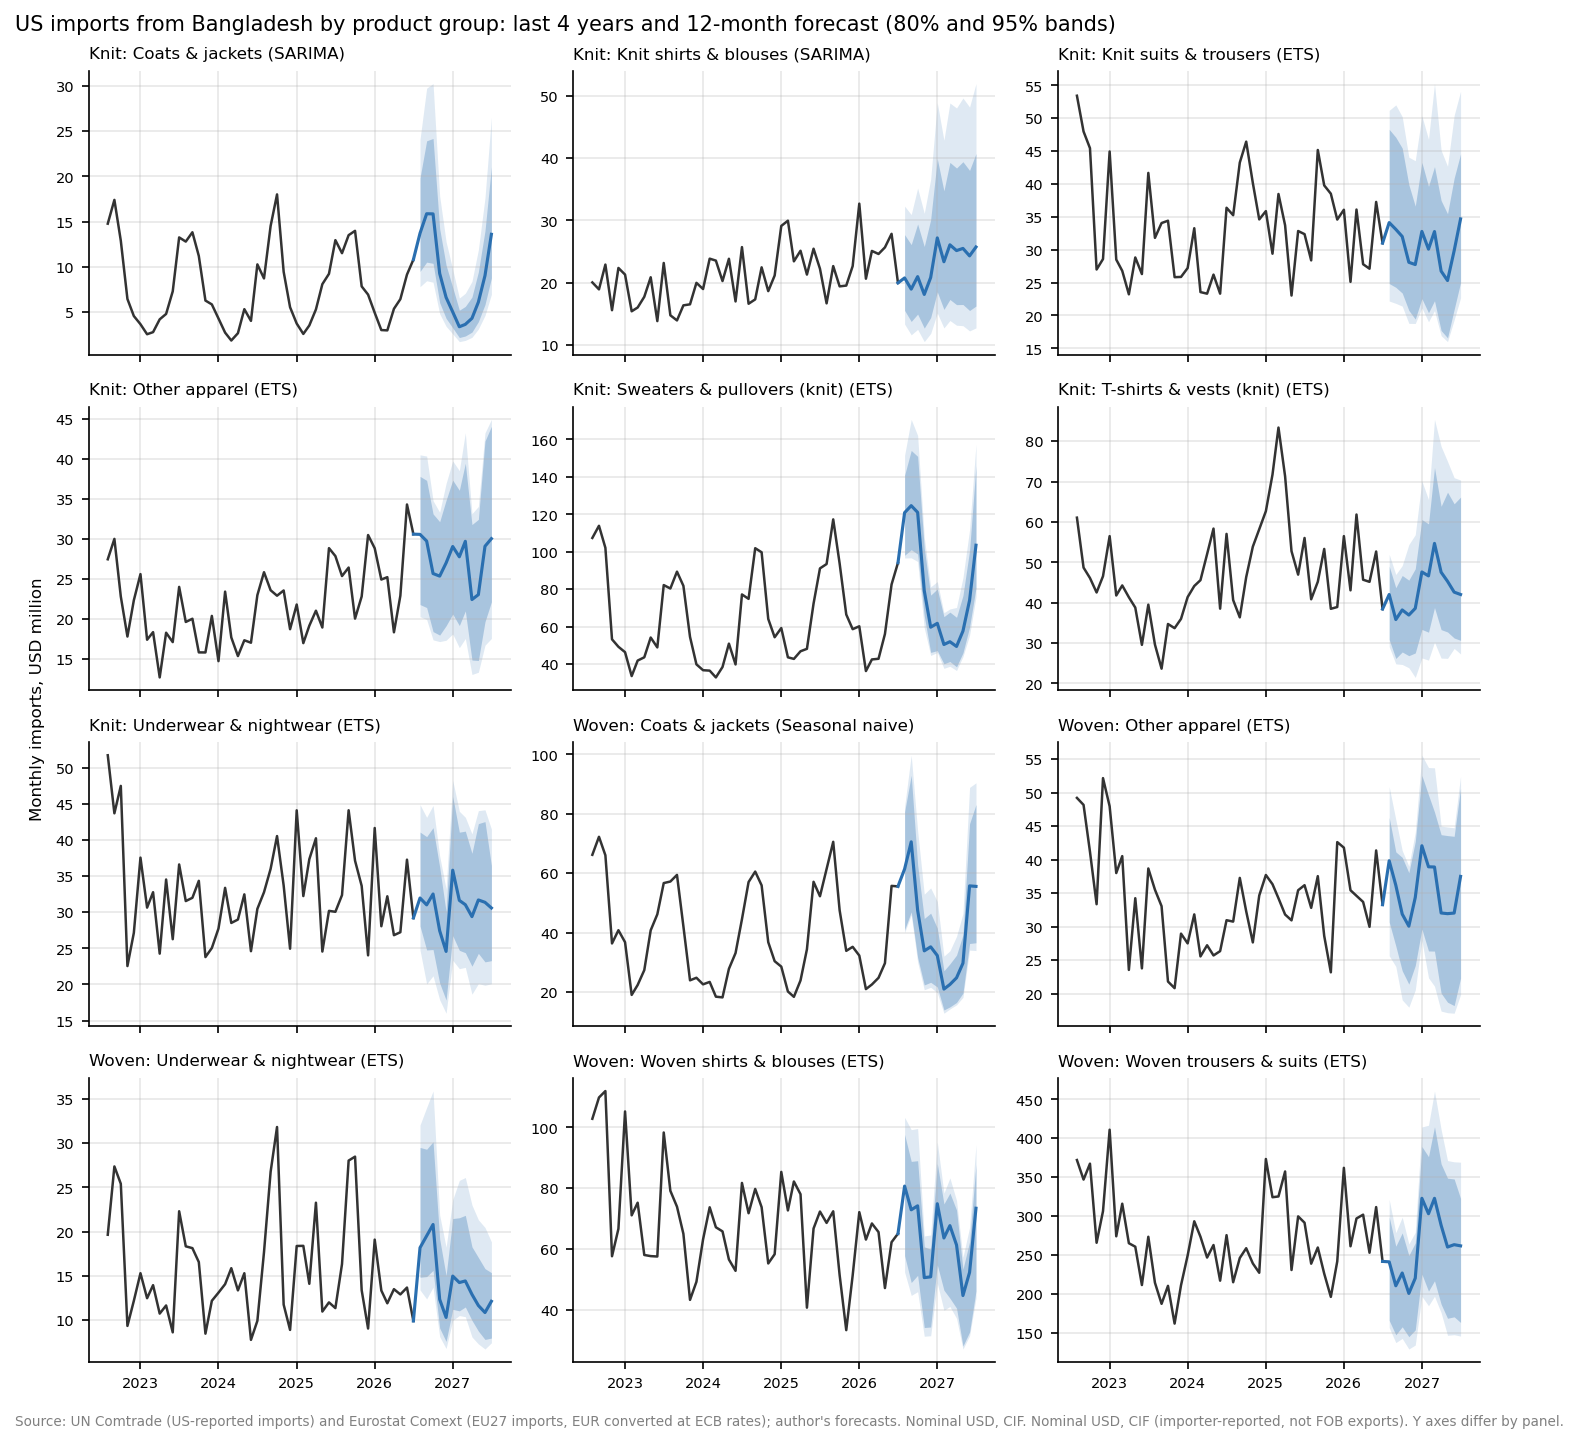

In [15]:
groups = [k for k in series if k.startswith("US | ") and k != "US | Total"]
fig, axes = plt.subplots(4, 3, figsize=(10, 9.5), sharex=True)
for ax, name in zip(axes.flat, groups):
    fan(name, ax)
    ax.set_title(f"{name[5:]} ({best_map[name]})", fontsize=8, loc="left"); ax.set_ylabel("")
    ax.tick_params(labelsize=7)
fig.supylabel("Monthly imports, USD million", fontsize=8)
fig.suptitle("US imports from Bangladesh by product group: last 4 years and 12-month forecast (80% and 95% bands)",
             x=0.01, ha="left", fontsize=10)
fig.text(0.01, -0.01, SOURCE + " Nominal USD, CIF (importer-reported, not FOB exports). Y axes differ by panel.", fontsize=6.5, color="grey")
fig.tight_layout(); fig.savefig(f"{FIG}/us_groups_forecast_small_multiples.png", bbox_inches="tight"); plt.show()

## Notes and limits

- These are forecasts of importer-reported CIF values, not Bangladesh's FOB export figures. See `outputs/QA_phase1.md`.
- The backtest covers mid-2022 to mid-2026, which includes the 2023 drop after the 2022 peak. Model rankings could differ in a calmer period.
- The forecasts do not include the November 2026 LDC graduation or US tariff changes. Those go in `03_scenarios.ipynb`.
- With seven origins, small differences between models are within noise. That is why the selection rule treats models within 1 point of 12-month-total APE as tied.
- Month-level forecasts are rough (monthly MAPE in the teens to twenties). Use the quarterly and annual totals for planning, not single months.